In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
from google.colab import files
files.upload()

Saving Astronomy_Followup_Priority_Perfect_Accuracy.csv to Astronomy_Followup_Priority_Perfect_Accuracy (1).csv


{'Astronomy_Followup_Priority_Perfect_Accuracy (1).csv': b'Spectral_Class,Star_Temperature_K,Luminosity_Solar,Distance_LY,Orbital_Period_Days,Planet_Radius_Earth,Star_Mass_Solar,Discovery_Year,Telescope,Detection_Method,Signal_Noise_Ratio,Followup_Priority_Code,Followup_Priority\nG,4872,5787.12134,2602.78,504.32,2.81,12.649,1997,Kepler,Microlensing,59.44,255,High\nF,9732,269.96019,1876.78,388.3,1.22,17.703,2012,Hubble,Radial Velocity,37.56,255,High\nA,22856,511.90829,801.95,291.99,7.71,15.178,2000,Kepler,Radial Velocity,19.02,0,Low\nA,2809,332.31517,1577.84,671.69,2.81,16.4,2010,JWST,Direct Imaging,72.84,0,Low\nM,19795,70279.49645,2431.72,113.68,14.88,16.67,2003,Hubble,Transit,93.6,127,Medium\nG,15181,45227.37693,554.04,124.72,9.83,10.885,2009,Hubble,Direct Imaging,15.98,255,High\nF,14849,16.02142,1564.06,162.88,5.87,21.605,2010,Kepler,Direct Imaging,54.51,127,Medium\nB,6446,0.00733,653.09,521.82,14.29,3.877,2014,JWST,Microlensing,3.91,0,Low\nB,21421,79682.28021,2106.94,411.55,4.91,4.2

In [ ]:
data = pd.read_csv("Astronomy_Followup_Priority_Perfect_Accuracy.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
data.head()

,Spectral_Class,Star_Temperature_K,Luminosity_Solar,Distance_LY,Orbital_Period_Days,Planet_Radius_Earth,Star_Mass_Solar,Discovery_Year,Telescope,Detection_Method,Signal_Noise_Ratio,Followup_Priority_Code,Followup_Priority
0,G,4872,5787.12134,2602.78,504.32,2.81,12.649,1997,Kepler,Microlensing,59.44,255,High
1,F,9732,269.96019,1876.78,388.30,1.22,17.703,2012,Hubble,Radial Velocity,37.56,255,High
2,A,22856,511.90829,801.95,291.99,7.71,15.178,2000,Kepler,Radial Velocity,19.02,0,Low
3,A,2809,332.31517,1577.84,671.69,2.81,16.400,2010,JWST,Direct Imaging,72.84,0,Low
4,M,19795,70279.49645,2431.72,113.68,14.88,16.670,2003,Hubble,Transit,93.60,127,Medium


In [ ]:
data.describe()

,Star_Temperature_K,Luminosity_Solar,Distance_LY,Orbital_Period_Days,Planet_Radius_Earth,Star_Mass_Solar,Discovery_Year,Signal_Noise_Ratio,Followup_Priority_Code
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,16220.046000,5352.087488,1497.901850,393.961755,7.540620,15.155009,2010.35300,51.125045,108.648000
std,8061.185657,14854.115041,868.470938,229.917414,4.209806,8.535117,9.25155,28.145699,101.357214
min,2425.000000,0.001010,2.120000,0.590000,0.300000,0.101000,1995.00000,1.060000,0.000000
25%,9049.250000,0.113080,753.220000,200.020000,3.947500,7.874500,2002.00000,27.327500,0.000000
50%,16208.500000,12.448695,1500.450000,392.945000,7.415000,15.223500,2010.00000,51.520000,127.000000
75%,23184.750000,1357.171263,2241.577500,585.087500,11.170000,22.403000,2018.00000,75.047500,255.000000
max,29991.000000,99864.021940,2999.650000,799.840000,15.000000,29.994000,2026.00000,99.980000,255.000000


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Spectral_Class          2000 non-null   object 
 1   Star_Temperature_K      2000 non-null   int64  
 2   Luminosity_Solar        2000 non-null   float64
 3   Distance_LY             2000 non-null   float64
 4   Orbital_Period_Days     2000 non-null   float64
 5   Planet_Radius_Earth     2000 non-null   float64
 6   Star_Mass_Solar         2000 non-null   float64
 7   Discovery_Year          2000 non-null   int64  
 8   Telescope               2000 non-null   object 
 9   Detection_Method        2000 non-null   object 
 10  Signal_Noise_Ratio      2000 non-null   float64
 11  Followup_Priority_Code  2000 non-null   int64  
 12  Followup_Priority       2000 non-null   object 
dtypes: float64(6), int64(3), object(4)
memory usage: 203.3+ KB


In [ ]:
data.isnull().sum()

,0
Spectral_Class,0
Star_Temperature_K,0
Luminosity_Solar,0
Distance_LY,0
Orbital_Period_Days,0
Planet_Radius_Earth,0
Star_Mass_Solar,0
Discovery_Year,0
Telescope,0
Detection_Method,0


In [ ]:
data.shape

(2000, 13)

In [ ]:
# Select Luminosity_Solar and Signal_Noise_Ratio as feature variables for clustering
X = data[['Luminosity_Solar', 'Signal_Noise_Ratio']]
print("Features selected for clustering: Luminosity_Solar and Signal_Noise_Ratio")

Features selected for clustering: Luminosity_Solar and Signal_Noise_Ratio


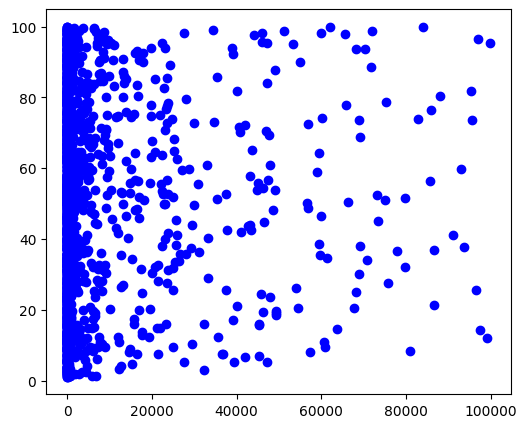

In [ ]:
# Visualize the original data points by plotting Luminosity against Signal-Noise Ratio
plt.figure(figsize=(6,5))
plt.scatter(
    X['Luminosity_Solar'],
    X['Signal_Noise_Ratio'],
    color='blue'
)

In [ ]:
# Apply StandardScaler to normalize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling complete using StandardScaler")

Feature scaling complete using StandardScaler


In [ ]:
# Initialize the K-Means algorithm with 3 clusters and train it on the scaled features
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_scaled)
print("Model trained successfully")

Model trained successfully


In [ ]:
# Assign cluster labels to the original dataset and display the first 5 rows
labels = kmeans.labels_
data['Cluster'] = labels
data[['Luminosity_Solar', 'Signal_Noise_Ratio', 'Cluster']].head()

,Luminosity_Solar,Signal_Noise_Ratio,Cluster
0,5787.12134,59.44,1
1,269.96019,37.56,0
2,511.90829,19.02,0
3,332.31517,72.84,1
4,70279.49645,93.60,2


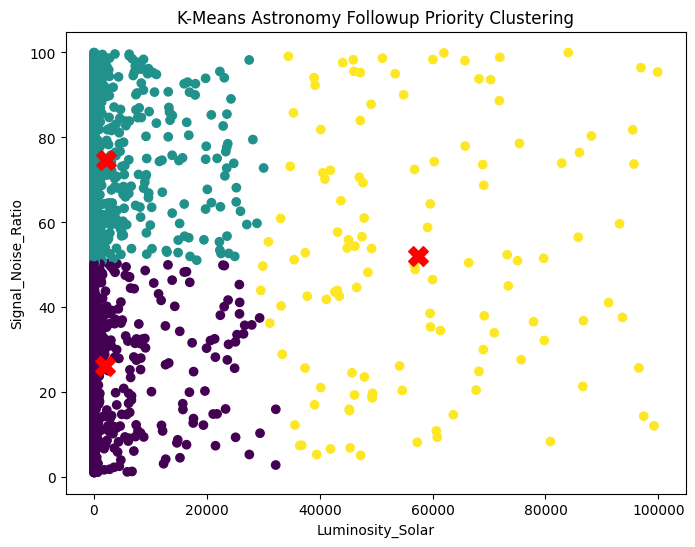

In [ ]:
# Visualize the clusters, with cluster centers marked
plt.figure(figsize=(8,6))
plt.scatter(
    X['Luminosity_Solar'],
    X['Signal_Noise_Ratio'],
    c=labels,
    cmap='viridis'
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centers[:,0],
    centers[:,1],
    c='red',
    s=200,
    marker='X'
)

plt.xlabel("Luminosity_Solar")
plt.ylabel("Signal_Noise_Ratio")
plt.title("K-Means Astronomy Followup Priority Clustering")
plt.show()

In [ ]:
# Calculate and display model evaluation metrics: Silhouette Score, WCSS (Inertia), Davies-Bouldin Index
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)

wcss = kmeans.inertia_
print("WCSS (Inertia):", wcss)

db_score = davies_bouldin_score(X_scaled, labels)
print("Davies-Bouldin Index:", db_score)

Silhouette Score: 0.5553690230406937
WCSS (Inertia): 1030.606811168962
Davies-Bouldin Index: 0.5852236785677257
